# Buy vs Rent

Compares two ways of living with the same income and lifestyle:

1. **Buy**: purchase an apartment with a mortgage, live in it (no rent), invest the monthly leftover into ETF
2. **Rent**: keep the capital in ETF, pay (cold) rent, invest the monthly leftover into ETF

Both scenarios run on the single unified model in `src/financial_model.py` — only the parameters differ.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

ROOT_DIR = Path("/Users/pkoshkin/code/personal/finantial-tools")
import sys
sys.path.append(str(ROOT_DIR))

from src.financial_model import (
    Scenario,
    simulate,
    replace,
    payoff_year,
    calculate_early_repayment_penalty,
)

In [2]:
CAPITAL = 100_000
MONTHLY_INCOME = 10_000
MONTHLY_RENT = 1_490
MONTHLY_SPENDING = 5_000
YEARLY_INCOME_INCREASE_RATE = 2 / 100
YEARLY_APARTMENT_RAISE_RATE = 3 / 100
YEARLY_RENT_INCREASE_RATE = 2 / 100
YEARLY_INFLATION_RATE = 2 / 100
YEARLY_ETF_RETURN_RATE = 7 / 100
MORTGAGE_APARTMENT_PRICE = 450_000
MORTGAGE_INTEREST_RATE = 3.8 / 100
MORTGAGE_DOWN_PAYMENT_RATE = 10 / 100
MORTGAGE_TOTAL_FEES_RATE = 10 / 100
MORTGAGE_YEARLY_REPAYMENT_RATE = 1.5 / 100
MORTGAGE_REFINANCING_YEARS = 10
YEARS = 30

common = dict(
    years=YEARS,
    initial_capital=CAPITAL,
    monthly_net_income=MONTHLY_INCOME,
    yearly_income_increase_rate=YEARLY_INCOME_INCREASE_RATE,
    monthly_spending=MONTHLY_SPENDING,
    yearly_inflation_rate=YEARLY_INFLATION_RATE,
    yearly_apartment_price_increase_rate=YEARLY_APARTMENT_RAISE_RATE,
    etf_yearly_return_rate=YEARLY_ETF_RETURN_RATE,
)

# Buy: own the apartment, pay the mortgage, no rent
buy_scenario = Scenario(
    apartment_price=MORTGAGE_APARTMENT_PRICE,
    mortgage_interest_rate=MORTGAGE_INTEREST_RATE,
    mortgage_down_payment_rate=MORTGAGE_DOWN_PAYMENT_RATE,
    mortgage_fees_rate=MORTGAGE_TOTAL_FEES_RATE,
    mortgage_yearly_repayment_rate=MORTGAGE_YEARLY_REPAYMENT_RATE,
    mortgage_refinancing_years=MORTGAGE_REFINANCING_YEARS,
    **common,
)

# Rent: no purchase, pay rent instead
rent_scenario = Scenario(
    monthly_rent=MONTHLY_RENT,
    yearly_rent_increase_rate=YEARLY_RENT_INCREASE_RATE,
    **common,
)

buy_model = simulate(buy_scenario)
rent_model = simulate(rent_scenario)

In [3]:
rent_model.head()

,year,total_loan,property_value,property_equity,etf_capital,etf_cost_basis,etf_capital_after_tax,estimated_total_capital,invested_capital,monthly_income,...,monthly_interest_payment,monthly_loan_repayment,monthly_mortgage_payment,monthly_housing_cost,monthly_leftover,yearly_sondertilgung,cumulative_interest_paid,yearly_etf_withdrawal_gross,yearly_etf_withdrawal_net,monthly_costs_not_covered_by_safe_withdrawal
0,0,0.0,0.0,0.0,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,10000.00,...,0.0,0.0,0.0,1490.00000,3510.000000,0.0,0.0,0.0,0.0,6240.000000
1,1,0.0,0.0,0.0,149896.366879,141571.966498,149896.366879,149896.366879,141571.966498,10000.00,...,0.0,0.0,0.0,1490.00000,3464.330541,0.0,0.0,0.0,0.0,6160.928541
2,2,0.0,0.0,0.0,204143.406776,183975.372326,204143.406776,204143.406776,183975.372326,10200.00,...,0.0,0.0,0.0,1519.80000,3533.617152,0.0,0.0,0.0,0.0,6156.024331
3,3,0.0,0.0,0.0,263062.825351,227226.846270,263062.825351,263062.825351,227226.846270,10404.00,...,0.0,0.0,0.0,1550.19600,3604.289495,0.0,0.0,0.0,0.0,6142.053441
4,4,0.0,0.0,0.0,326999.190829,271343.349694,326999.190829,326999.190829,271343.349694,10612.08,...,0.0,0.0,0.0,1581.19992,3676.375285,0.0,0.0,0.0,0.0,6118.206738


In [4]:
buy_model.head()

,year,total_loan,property_value,property_equity,etf_capital,etf_cost_basis,etf_capital_after_tax,estimated_total_capital,invested_capital,monthly_income,...,monthly_interest_payment,monthly_loan_repayment,monthly_mortgage_payment,monthly_housing_cost,monthly_leftover,yearly_sondertilgung,cumulative_interest_paid,yearly_etf_withdrawal_gross,yearly_etf_withdrawal_net,monthly_costs_not_covered_by_safe_withdrawal
0,0,405000.000000,450000.0000,45000.000000,10000.000000,10000.000000,10000.000000,55000.000000,100000.000000,10000.00,...,0.000000,0.000000,1788.75,1788.75,3211.250000,0.0,0.000000,0.0,0.0,6763.750000
1,1,398818.068908,463500.0000,64681.931092,49897.753106,47986.966498,49897.753106,114579.684198,137986.966498,10000.00,...,1273.589076,515.160924,1788.75,1788.75,3165.580541,0.0,15283.068908,0.0,0.0,6709.675076
2,2,392397.089531,477405.0000,85007.910469,93815.209123,87162.972326,93815.209123,178823.119592,177162.972326,10200.00,...,1253.668385,535.081615,1788.75,1788.75,3264.667152,0.0,30327.089531,0.0,0.0,6700.794825
3,3,385727.818140,491727.1500,105999.331860,142058.284457,127551.798270,142058.284457,248057.616317,217551.798270,10404.00,...,1232.977384,555.772616,1788.75,1788.75,3365.735495,0.0,45122.818140,0.0,0.0,6683.118793
4,4,378800.653565,506478.9645,127678.310935,194954.800408,169177.700734,194954.800408,322633.111343,259177.700734,10612.08,...,1211.486285,577.263715,1788.75,1788.75,3468.825205,0.0,59660.653565,0.0,0.0,6655.867794


In [5]:
rent_model.tail()

,year,total_loan,property_value,property_equity,etf_capital,etf_cost_basis,etf_capital_after_tax,estimated_total_capital,invested_capital,monthly_income,...,monthly_interest_payment,monthly_loan_repayment,monthly_mortgage_payment,monthly_housing_cost,monthly_leftover,yearly_sondertilgung,cumulative_interest_paid,yearly_etf_withdrawal_gross,yearly_etf_withdrawal_net,monthly_costs_not_covered_by_safe_withdrawal
26,26,0.0,0.0,0.0,4.127351e+06,1.499766e+06,4.127351e+06,4.127351e+06,1.499766e+06,16406.059945,...,0.0,0.0,0.0,2444.502932,5683.601453,0.0,0.0,0.0,0.0,404.081046
27,27,0.0,0.0,0.0,4.488049e+06,1.569333e+06,4.488049e+06,4.488049e+06,1.569333e+06,16734.181144,...,0.0,0.0,0.0,2493.392990,5797.273482,0.0,0.0,0.0,0.0,-283.215099
28,28,0.0,0.0,0.0,4.875432e+06,1.640292e+06,4.875432e+06,4.875432e+06,1.640292e+06,17068.864766,...,0.0,0.0,0.0,2543.260850,5913.218952,0.0,0.0,0.0,0.0,-1032.933610
29,29,0.0,0.0,0.0,5.291396e+06,1.712669e+06,5.291396e+06,5.291396e+06,1.712669e+06,17410.242062,...,0.0,0.0,0.0,2594.126067,6031.483331,0.0,0.0,0.0,0.0,-1849.730286
30,30,0.0,0.0,0.0,5.737971e+06,1.786495e+06,5.737971e+06,5.737971e+06,1.786495e+06,17758.446903,...,0.0,0.0,0.0,2646.008589,6152.112998,0.0,0.0,0.0,0.0,-2738.592556


In [6]:
buy_model.tail()

,year,total_loan,property_value,property_equity,etf_capital,etf_cost_basis,etf_capital_after_tax,estimated_total_capital,invested_capital,monthly_income,...,monthly_interest_payment,monthly_loan_repayment,monthly_mortgage_payment,monthly_housing_cost,monthly_leftover,yearly_sondertilgung,cumulative_interest_paid,yearly_etf_withdrawal_gross,yearly_etf_withdrawal_net,monthly_costs_not_covered_by_safe_withdrawal
26,26,243569.707797,9.704661e+05,726896.362598,3.745057e+06,1.535449e+06,3.745057e+06,4.471953e+06,1.625449e+06,16406.059945,...,779.928262,416.574305,1196.502567,1196.502567,6931.601818,0.0,314922.764729,0.0,0.0,111.816368
27,27,238377.514651,9.995801e+05,761202.537855,4.095050e+06,1.620578e+06,4.095050e+06,4.856253e+06,1.710578e+06,16734.181144,...,763.819805,432.682762,1196.502567,1196.502567,7094.163906,0.0,324088.602387,0.0,0.0,-597.608060
28,28,232984.545268,1.029567e+06,796582.908814,4.471596e+06,1.707698e+06,4.471596e+06,5.268179e+06,1.797698e+06,17068.864766,...,747.088452,449.414115,1196.502567,1196.502567,7259.977235,0.0,333053.663808,0.0,0.0,-1370.102778
29,29,227383.035855,1.060454e+06,833071.441849,4.876594e+06,1.796847e+06,4.876594e+06,5.709666e+06,1.886847e+06,17410.242062,...,729.710116,466.792451,1196.502567,1196.502567,7429.106831,0.0,341810.185199,0.0,0.0,-2210.350918
30,30,221564.922407,1.092268e+06,870703.189628,5.312079e+06,1.888067e+06,5.312079e+06,6.182782e+06,1.978067e+06,17758.446903,...,711.659780,484.842787,1196.502567,1196.502567,7601.619019,0.0,350350.102555,0.0,0.0,-3123.368797


In [7]:
def plot_buy_vs_rent(field: str):
    """Positive values mean buying beats renting for this indicator.

    Year 0 already shows the true post-purchase state: the purchase fees
    are sunk immediately, so the buy scenario starts behind."""
    deltas = buy_model[field] - rent_model[field]
    years = list(range(0, YEARS + 1))
    plt.figure(figsize=(15, 5))
    plt.plot(years, deltas, label="Buy over rent", color="Green", marker='o')
    plt.xlabel("Year")
    plt.ylabel("Buying over renting")
    plt.xticks(years)
    plt.axhline(0, label="Zero")
    plt.legend()
    plt.show()


def plot_field(model, field: str):
    values = model[field]
    years = list(range(0, YEARS + 1))
    plt.figure(figsize=(15, 5))
    plt.plot(years, values, color="Green", marker='o')
    plt.xlabel("Year")
    plt.ylabel(field)
    plt.xticks(years)
    plt.axhline(0)
    plt.show()

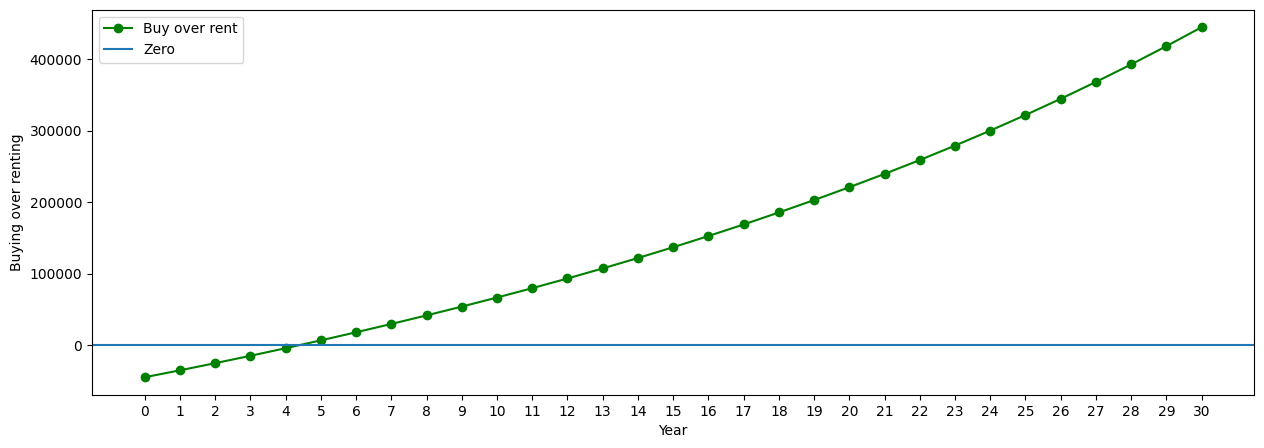

In [8]:
plot_buy_vs_rent(field="estimated_total_capital")

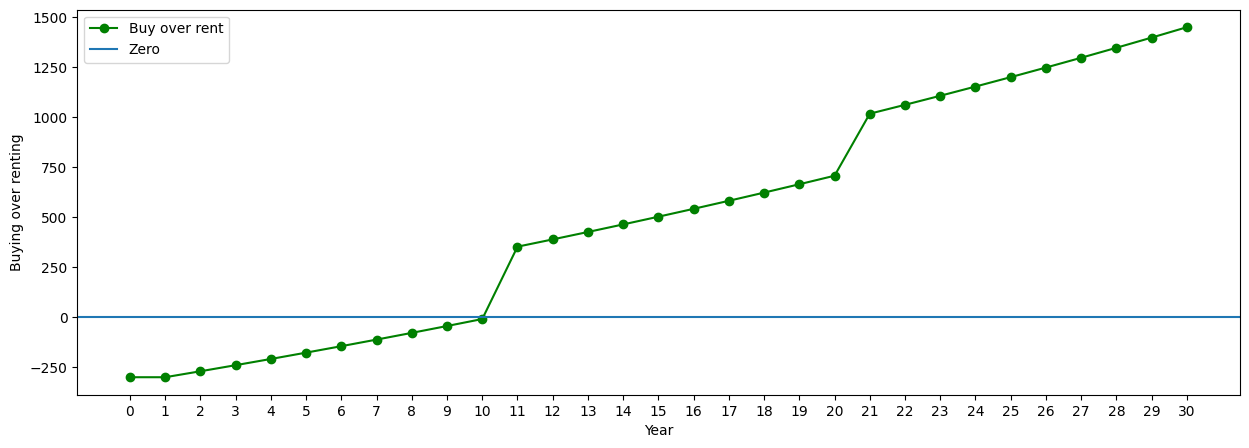

In [9]:
plot_buy_vs_rent(field="monthly_leftover")

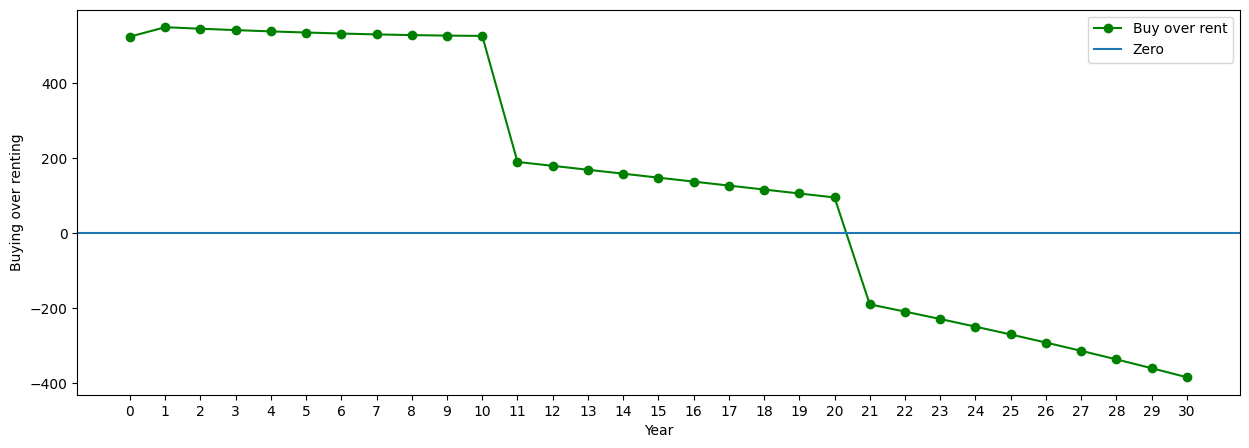

In [10]:
plot_buy_vs_rent(field="monthly_costs_not_covered_by_safe_withdrawal")

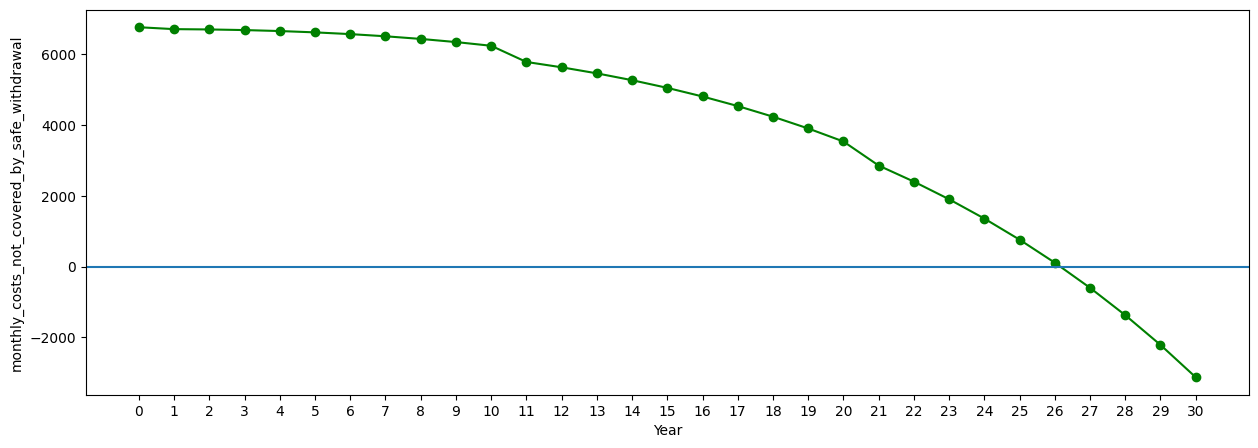

In [11]:
plot_field(model=buy_model, field="monthly_costs_not_covered_by_safe_withdrawal")

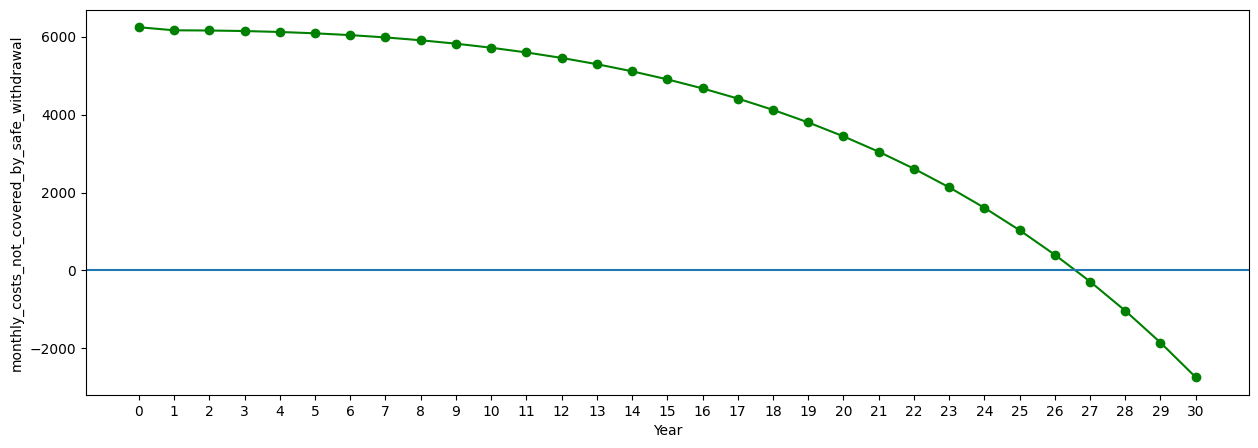

In [12]:
plot_field(model=rent_model, field="monthly_costs_not_covered_by_safe_withdrawal")

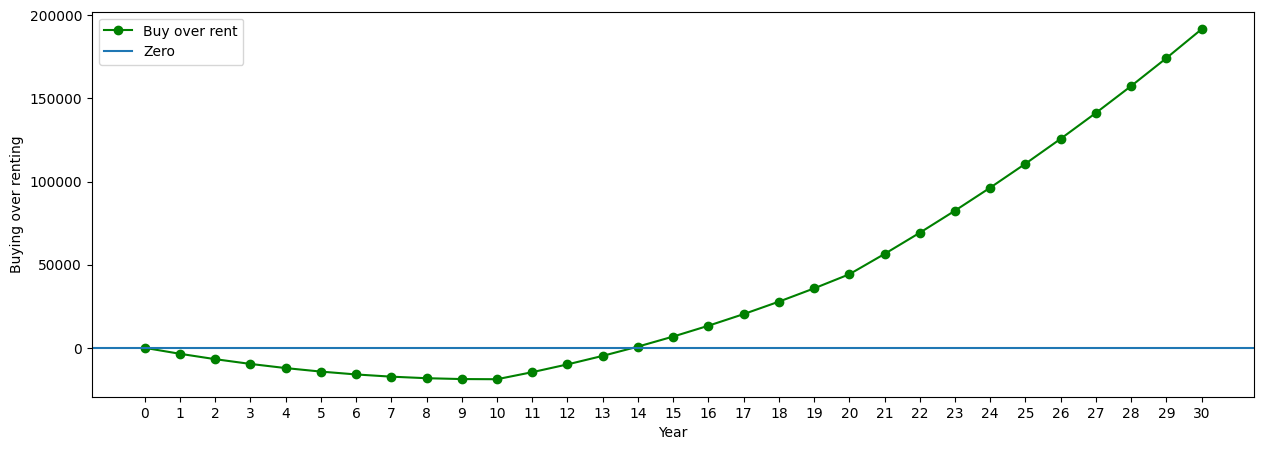

In [13]:
plot_buy_vs_rent(field="invested_capital")

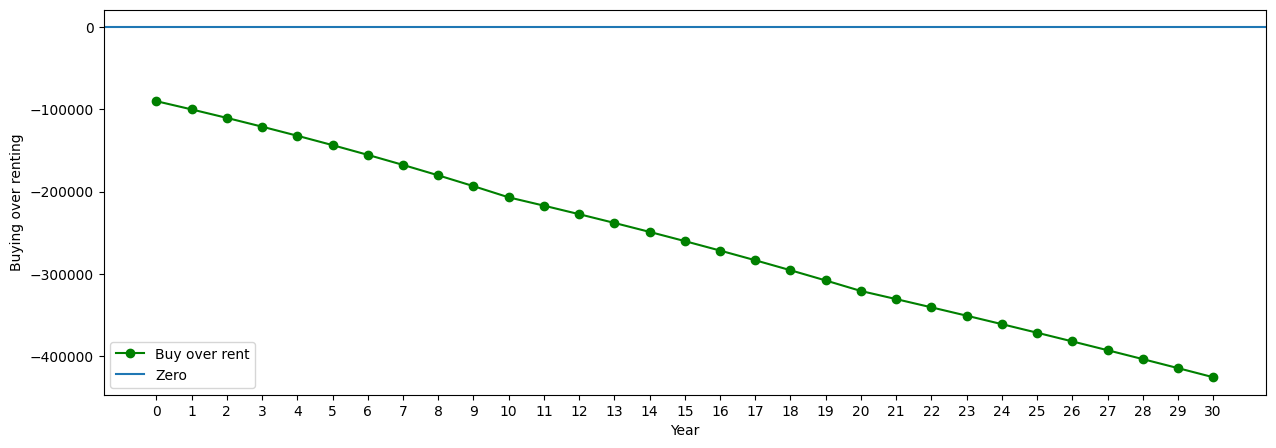

In [14]:
plot_buy_vs_rent(field="etf_capital")

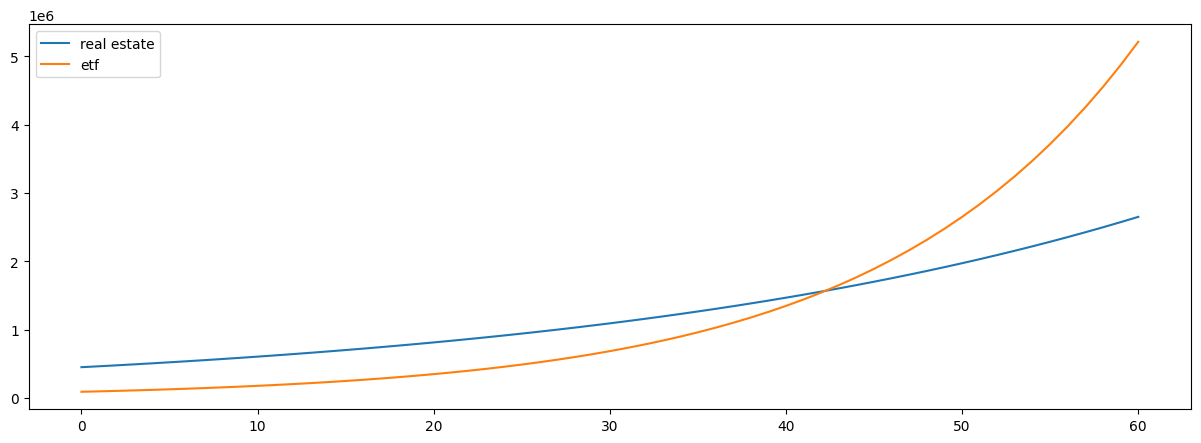

In [15]:
def capital_and_income(init_capital, interest):
    capitals = [init_capital]
    for y in range(60):
        capitals.append(capitals[-1] * (1 + interest))
    return np.array(capitals)

plt.figure(figsize=(15, 5))
plt.plot(capital_and_income(init_capital=450_000, interest=3/100), label="real estate")
plt.plot(capital_and_income(init_capital=450_000 * 0.2, interest=7/100), label="etf")
plt.legend()